<a href="https://colab.research.google.com/github/Aayush1509-PROG/Cognitive-Computing-Assignments/blob/main/Assignment%2010.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [39]:
# UCS420: Cognitive Computing
# Assignment 10 - Diabetes Care Information Assistant
# Submitted by: Aayush A Sapra | Roll No.: 1024170351
# Odd roll number topic: Diabetes Care Information Assistant

!pip -q install nltk scikit-learn pandas matplotlib seaborn

In [40]:
import re
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Download the language resources used for tokenization, stopword removal
# and lemmatization. These downloads are supported in Google Colab.
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

print("Libraries imported successfully.")

Libraries imported successfully.


In [41]:
# Labelled corpus: 75 sample queries across 5 diabetes-care intent categories.
# The queries are illustrative training examples for an academic prototype.

data = {
    "symptoms": [
        "What are common signs and symptoms of diabetes?",
        "Can diabetes cause frequent urination?",
        "Why am I always thirsty and tired?",
        "Is blurry vision a possible symptom of diabetes?",
        "Can unexplained weight loss be linked to diabetes?",
        "Do people with diabetes feel hungry more often?",
        "Can slow healing cuts be related to diabetes?",
        "Can someone have diabetes without obvious symptoms?",
        "What are common warning signs of high blood sugar?",
        "Can recurring infections be associated with diabetes?",
        "What are early signs of type 2 diabetes?",
        "Can high blood sugar make someone feel tired?",
        "Can diabetes cause tingling in the hands or feet?",
        "Why do I feel thirsty even after drinking water?",
        "Are symptoms alone enough to know if I have diabetes?"
    ],

    "monitoring": [
        "How do I check my blood sugar at home?",
        "What is a blood glucose meter used for?",
        "How often should I monitor my glucose?",
        "What does an A1C test measure?",
        "Does A1C show average blood sugar over time?",
        "What is the difference between a glucose meter and an A1C test?",
        "Why should I record my blood glucose readings?",
        "When should I discuss glucose readings with my doctor?",
        "What is continuous glucose monitoring?",
        "How can I understand trends in my blood sugar readings?",
        "What is a fasting blood glucose test?",
        "How can I track my daily glucose results?",
        "Why does my doctor ask for regular A1C tests?",
        "Does an A1C test show my blood sugar at one exact moment?",
        "What information does a glucose monitor provide?"
    ],

    "nutrition": [
        "What foods are helpful in a diabetes meal plan?",
        "Which drinks should I limit if I have diabetes?",
        "How do carbohydrates affect blood glucose?",
        "Is portion control important for diabetes?",
        "What is the diabetes plate method?",
        "Are whole grains a useful choice for diabetes?",
        "How can I plan balanced meals?",
        "Do sugary drinks raise blood sugar?",
        "What are examples of non starchy vegetables?",
        "Should I follow a personalised meal plan?",
        "Are fruits allowed in a diabetes meal plan?",
        "Should I choose water instead of sugary drinks?",
        "How can I balance carbohydrates in my meals?",
        "What does portion size mean for diabetes?",
        "Can beans and lentils be part of a balanced diabetes meal?"
    ],

    "lifestyle": [
        "What physical activity can support diabetes management?",
        "Can walking help with blood sugar management?",
        "Why is regular exercise important for diabetes?",
        "How can I start being active safely?",
        "Does sleep matter for diabetes management?",
        "Can stress affect blood glucose levels?",
        "How often should adults be physically active?",
        "What lifestyle habits may lower the risk of type 2 diabetes?",
        "Why should people with diabetes avoid smoking?",
        "How can I build a healthy daily routine?",
        "Can a short walk after meals support blood sugar management?",
        "How does sleep affect my glucose level?",
        "Can stress make diabetes harder to manage?",
        "What activities count as moderate physical activity?",
        "How can I reduce long periods of sitting?"
    ],

    "medication": [
        "What medicines are used to manage diabetes?",
        "Why might a person with diabetes need insulin?",
        "Is insulin used for type 1 diabetes?",
        "What should I do if I have side effects from diabetes medicine?",
        "Who decides which diabetes medicine is suitable?",
        "How should I take my prescribed diabetes medicine?",
        "Can diabetes medicines differ between people?",
        "What questions should I ask my doctor about insulin?",
        "Why are some people prescribed more than one diabetes medicine?",
        "Can medicines help control blood glucose levels?",
        "Why do some people with type 2 diabetes take tablets?",
        "Does everyone with diabetes need insulin?",
        "What should I discuss with a pharmacist about medicine side effects?",
        "Can diabetes treatment depend on other health conditions?",
        "Should I take prescribed medicine even when I feel well?"
    ]
}

df = pd.DataFrame([
    {"query": query, "intent": intent}
    for intent, queries in data.items()
    for query in queries
])

print("Total queries:", len(df))
print("\nQueries per intent:")
print(df["intent"].value_counts())

df.head()

Total queries: 75

Queries per intent:
intent
symptoms      15
monitoring    15
nutrition     15
lifestyle     15
medication    15
Name: count, dtype: int64


,query,intent
0,What are common signs and symptoms of diabetes?,symptoms
1,Can diabetes cause frequent urination?,symptoms
2,Why am I always thirsty and tired?,symptoms
3,Is blurry vision a possible symptom of diabetes?,symptoms
4,Can unexplained weight loss be linked to diabe...,symptoms


In [42]:
# Hierarchical taxonomy: 4 major categories with 2 subcategories each.

taxonomy = {
    "Diabetes Foundations": [
        "Symptoms and warning signs",
        "Types and risk factors"
    ],

    "Monitoring and Assessment": [
        "Blood glucose monitoring",
        "A1C and laboratory tests"
    ],

    "Daily Self-Management": [
        "Nutrition and meal planning",
        "Physical activity and healthy routines"
    ],

    "Treatment and Safety": [
        "Medication information",
        "Complications and emergency support"
    ]
}

for category, subcategories in taxonomy.items():
    print(category)

    for subcategory in subcategories:
        print("  └──", subcategory)

Diabetes Foundations
  └── Symptoms and warning signs
  └── Types and risk factors
Monitoring and Assessment
  └── Blood glucose monitoring
  └── A1C and laboratory tests
Daily Self-Management
  └── Nutrition and meal planning
  └── Physical activity and healthy routines
Treatment and Safety
  └── Medication information
  └── Complications and emergency support


In [43]:
# Domain concepts and their relationships for the diabetes knowledge model.

concepts = {
    "Diabetes": "A health condition involving problems with blood glucose regulation.",
    "Blood Glucose": "The amount of glucose, or sugar, present in the blood.",
    "Insulin": "A hormone that helps glucose move from the blood into body cells.",
    "Insulin Resistance": "A condition in which body cells respond less effectively to insulin.",
    "Hyperglycemia": "A condition in which blood glucose is higher than the target range.",
    "Hypoglycemia": "A condition in which blood glucose is lower than the target range.",
    "Severe Hypoglycemia": "A dangerously low blood glucose event in which a person may need help.",
    "HbA1c": "A blood test that reflects average blood glucose over about three months.",
    "Glucose Meter": "A device used to measure blood glucose at a particular time.",
    "Carbohydrates": "Nutrients in foods that can raise blood glucose after eating.",
    "Physical Activity": "Body movement that can support health and diabetes management.",
    "Medication": "A prescribed treatment used to help manage a health condition.",
    "Type 1 Diabetes": "A type of diabetes in which the body makes little or no insulin.",
    "Type 2 Diabetes": "A type of diabetes in which the body does not use insulin effectively.",
    "Diabetic Ketoacidosis": "A serious diabetes-related condition involving a dangerous build-up of ketones.",
    "Healthcare Professional": "A trained person who provides medical care and guidance.",
    "Emergency Care": "Urgent medical support for a serious or life-threatening condition.",
    "Diabetes Care Plan": "A personalised plan made with a healthcare team to manage diabetes."
}

relationships = [
    ("Diabetes", "involves regulation of", "Blood Glucose"),
    ("Insulin", "helps move", "Blood Glucose"),
    ("Type 1 Diabetes", "involves little or no production of", "Insulin"),
    ("Type 2 Diabetes", "is often associated with", "Insulin Resistance"),
    ("Insulin Resistance", "reduces the body's response to", "Insulin"),
    ("Hyperglycemia", "describes high levels of", "Blood Glucose"),
    ("Hypoglycemia", "describes low levels of", "Blood Glucose"),
    ("HbA1c", "estimates average", "Blood Glucose"),
    ("Glucose Meter", "measures", "Blood Glucose"),
    ("Carbohydrates", "can raise", "Blood Glucose"),
    ("Physical Activity", "can support management of", "Blood Glucose"),
    ("Medication", "may be used to manage", "Diabetes"),
    ("Diabetic Ketoacidosis", "is a serious complication of", "Diabetes"),
    ("Severe Hypoglycemia", "may require urgent", "Emergency Care"),
    ("Healthcare Professional", "guides the use of", "Medication"),
    ("Healthcare Professional", "helps create a", "Diabetes Care Plan"),
    ("Diabetes Care Plan", "may include monitoring of", "Blood Glucose")
]

print("Domain Concepts:")
for concept, definition in concepts.items():
    print(f"{concept}: {definition}")

print("\nKnowledge Model Relationships:")
for subject, relation, obj in relationships:
    print(f"{subject} --{relation}--> {obj}")

print("\nTotal concepts:", len(concepts))
print("Total relationships:", len(relationships))

Domain Concepts:
Diabetes: A health condition involving problems with blood glucose regulation.
Blood Glucose: The amount of glucose, or sugar, present in the blood.
Insulin: A hormone that helps glucose move from the blood into body cells.
Insulin Resistance: A condition in which body cells respond less effectively to insulin.
Hyperglycemia: A condition in which blood glucose is higher than the target range.
Hypoglycemia: A condition in which blood glucose is lower than the target range.
Severe Hypoglycemia: A dangerously low blood glucose event in which a person may need help.
HbA1c: A blood test that reflects average blood glucose over about three months.
Glucose Meter: A device used to measure blood glucose at a particular time.
Carbohydrates: Nutrients in foods that can raise blood glucose after eating.
Physical Activity: Body movement that can support health and diabetes management.
Medication: A prescribed treatment used to help manage a health condition.
Type 1 Diabetes: A type

In [44]:
# Text preprocessing: lowercase conversion, punctuation removal,
# tokenization, stopword removal and lemmatization.

stop_words = set(stopwords.words("english"))

# Keep negation words because "no", "not" and "never" can change meaning.
stop_words = stop_words - {"no", "not", "nor", "never"}

lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = str(text).lower()

    # Keep letters and spaces; remove punctuation and numbers.
    text = re.sub(r"[^a-z\s]", " ", text)

    # Tokenization.
    tokens = word_tokenize(text)

    # Stopword removal and lemmatization.
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words
    ]

    return " ".join(tokens)

df["processed_query"] = df["query"].apply(preprocess_text)

print(df[["query", "processed_query", "intent"]].head(10))

                                               query  \
0    What are common signs and symptoms of diabetes?   
1             Can diabetes cause frequent urination?   
2                 Why am I always thirsty and tired?   
3   Is blurry vision a possible symptom of diabetes?   
4  Can unexplained weight loss be linked to diabe...   
5    Do people with diabetes feel hungry more often?   
6      Can slow healing cuts be related to diabetes?   
7  Can someone have diabetes without obvious symp...   
8  What are common warning signs of high blood su...   
9  Can recurring infections be associated with di...   

                            processed_query    intent  
0              common sign symptom diabetes  symptoms  
1         diabetes cause frequent urination  symptoms  
2                      always thirsty tired  symptoms  
3   blurry vision possible symptom diabetes  symptoms  
4   unexplained weight loss linked diabetes  symptoms  
5         people diabetes feel hungry often  sy

In [45]:
# TF-IDF feature extraction and Logistic Regression intent classifier.

X = df["processed_query"]
y = df["intent"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

model.fit(X_train, y_train)

print("Model training completed.")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Intent categories:", list(model.classes_))

Model training completed.
Training samples: 56
Testing samples: 19
Intent categories: ['lifestyle', 'medication', 'monitoring', 'nutrition', 'symptoms']


In [46]:
# Evaluate the classifier using the required performance metrics.

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, average="weighted", zero_division=0
)
recall = recall_score(
    y_test, y_pred, average="weighted", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

print("Accuracy:", round(accuracy, 3))
print("Precision:", round(precision, 3))
print("Recall:", round(recall, 3))
print("F1-score:", round(f1, 3))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nNote: This is a small educational dataset. These scores describe this train/test split only; they do not validate the assistant for clinical use.")

Accuracy: 0.684
Precision: 0.758
Recall: 0.684
F1-score: 0.692

Classification Report:
              precision    recall  f1-score   support

   lifestyle       0.50      0.50      0.50         4
  medication       0.40      0.67      0.50         3
  monitoring       0.80      1.00      0.89         4
   nutrition       1.00      0.50      0.67         4
    symptoms       1.00      0.75      0.86         4

    accuracy                           0.68        19
   macro avg       0.74      0.68      0.68        19
weighted avg       0.76      0.68      0.69        19


Note: This is a small educational dataset. These scores describe this train/test split only; they do not validate the assistant for clinical use.


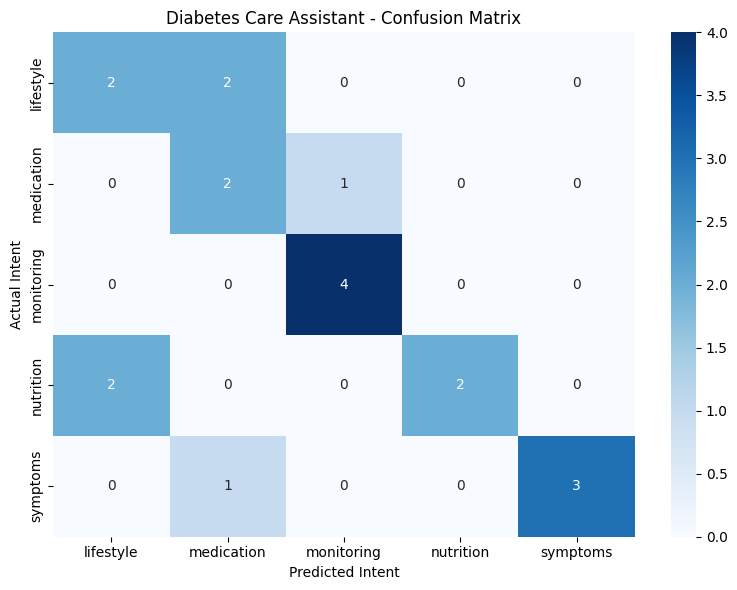

In [47]:
# Visualise the confusion matrix.

labels = model.classes_
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")
plt.title("Diabetes Care Assistant - Confusion Matrix")
plt.tight_layout()
plt.show()

In [48]:
# Domain-specific knowledge base.
# The information below is general education, not personal medical advice.

knowledge_base = {
    "symptoms": """
    Possible symptoms of diabetes include frequent urination, increased thirst
    or hunger, unexplained weight loss, tiredness and blurry vision. Some people
    may have few or no noticeable symptoms. Symptoms alone cannot confirm
    diabetes. A qualified healthcare professional can recommend and interpret
    appropriate tests.
    """,

    "monitoring": """
    A blood glucose meter measures blood glucose at a particular time. An A1C
    blood test gives information about average blood glucose over approximately
    the past three months. How often someone should check glucose and what
    targets are suitable depend on their health and treatment plan. Follow the
    monitoring advice provided by the healthcare team.
    """,

    "nutrition": """
    A balanced diabetes meal plan can include non-starchy vegetables, suitable
    sources of protein, whole grains and appropriate portions of carbohydrate
    foods. Carbohydrates can raise blood glucose. The plate method is one
    practical guide: half the plate with non-starchy vegetables, one quarter
    with lean protein and one quarter with carbohydrate foods. Individual
    nutrition needs differ, so a clinician or registered dietitian can help
    create a suitable plan.
    """,

    "lifestyle": """
    Regular physical activity can support blood glucose management, heart
    health, sleep and general well-being. Walking is one possible activity.
    Start at a comfortable level and increase gradually. The right activity
    plan depends on a person's health, fitness and complications, so ask a
    healthcare professional before starting a new or difficult exercise plan.
    Adequate sleep, stress management and avoiding tobacco can also support
    overall health.
    """,

    "medication": """
    Diabetes medicines vary according to the type of diabetes, blood glucose
    levels and other health conditions. Some people use tablets, some use
    injectable medicines, and people with type 1 diabetes need insulin.
    Medicines should be taken as prescribed. Do not start, stop or change a
    medicine or dose based on this assistant. Discuss side effects, missed
    doses or treatment questions with a doctor or pharmacist.
    """
}

# Reference sources used to prepare the general educational content.
knowledge_sources = {
    "Symptoms": "CDC - https://www.cdc.gov/diabetes/signs-symptoms/",
    "Monitoring and A1C": "NIDDK - https://www.niddk.nih.gov/health-information/diagnostic-tests/a1c-test",
    "Nutrition": "CDC - https://www.cdc.gov/diabetes/healthy-eating/diabetes-meal-planning.html",
    "Lifestyle": "CDC - https://www.cdc.gov/diabetes/living-with/physical-activity.html",
    "Medication": "NIDDK - https://www.niddk.nih.gov/health-information/diabetes/overview/insulin-medicines-treatments"
}

print("Knowledge base created for", len(knowledge_base), "intent categories.")
print("\nInformation sources:")
for topic, source in knowledge_sources.items():
    print(f"{topic}: {source}")

Knowledge base created for 5 intent categories.

Information sources:
Symptoms: CDC - https://www.cdc.gov/diabetes/signs-symptoms/
Monitoring and A1C: NIDDK - https://www.niddk.nih.gov/health-information/diagnostic-tests/a1c-test
Nutrition: CDC - https://www.cdc.gov/diabetes/healthy-eating/diabetes-meal-planning.html
Lifestyle: CDC - https://www.cdc.gov/diabetes/living-with/physical-activity.html
Medication: NIDDK - https://www.niddk.nih.gov/health-information/diabetes/overview/insulin-medicines-treatments


In [49]:
# Rule-based reasoning and response generation.

EMERGENCY_KEYWORDS = [
    "unconscious",
    "unresponsive",
    "seizure",
    "cannot wake",
    "can't wake",
    "not waking",
    "severe low blood sugar",
    "severe hypoglycemia",
    "diabetic ketoacidosis",
    "fruity breath",
    "high ketones",
    "difficulty breathing",
    "trouble breathing",
    "deep rapid breathing"
]

MEDICATION_SAFETY_PHRASES = [
    "change my dose",
    "change the dose",
    "increase my dose",
    "reduce my dose",
    "double my dose",
    "stop taking",
    "stop my medicine",
    "skip my medication",
    "missed dose",
    "how much insulin",
    "insulin dose",
    "what dose should i take"
]

SUPPORTED_TERMS = [
    "diabetes", "diabetic", "blood sugar", "blood glucose", "glucose",
    "insulin", "a1c", "hba1c", "hyperglycemia", "hypoglycemia",
    "thirst", "thirsty", "urinate", "urination", "pee", "blurry vision",
    "blurred vision", "carbohydrate", "carbs", "meal plan", "glucose meter",
    "sugar level", "blood sugar level", "diabetes medicine", "diabetes medication"
]

CONFIDENCE_THRESHOLD = 0.30

def is_emergency(query):
    query = query.lower()

    if any(keyword in query for keyword in EMERGENCY_KEYWORDS):
        return True

    # Vomiting together with breathing difficulty can be a warning sign
    # of a serious diabetes-related emergency.
    if "vomit" in query and any(
        phrase in query for phrase in [
            "deep breathing", "rapid breathing",
            "difficulty breathing", "trouble breathing", "fruity breath"
        ]
    ):
        return True

    return False


def get_response(query):
    query = str(query).strip()

    if not query:
        return "Please enter a question about diabetes care."

    # Rule 1: Emergency escalation.
    if is_emergency(query):
        return (
            "EMERGENCY ALERT: This may be a serious medical emergency. "
            "Call your local emergency number or go to the nearest emergency "
            "department immediately. If the person is unconscious or unable "
            "to swallow, do not give food or drink by mouth. Follow emergency "
            "dispatcher instructions. This assistant cannot manage emergencies."
        )

    # Rule 2: Unsupported-query handling.
    if not any(term in query.lower() for term in SUPPORTED_TERMS):
        return (
            "Sorry, this question appears to be outside my diabetes-care "
            "knowledge base. I can provide general educational information "
            "about diabetes symptoms, glucose monitoring, nutrition, lifestyle "
            "and medication."
        )

    # Rule 3: Medication safety.
    if any(phrase in query.lower() for phrase in MEDICATION_SAFETY_PHRASES):
        return (
            "MEDICATION SAFETY: I cannot recommend or calculate a personal "
            "medicine or insulin dose. Do not stop or change prescribed "
            "treatment based on this assistant. Contact your doctor or "
            "pharmacist for advice about a missed dose, side effect or dose change."
        )

    # Rule 4: Predict intent and calculate confidence.
    processed_query = preprocess_text(query)

    if not processed_query.strip():
        return (
            "I could not understand the question. Please rephrase it using "
            "words related to diabetes care."
        )

    probabilities = model.predict_proba([processed_query])[0]
    predicted_index = np.argmax(probabilities)
    predicted_intent = model.classes_[predicted_index]
    confidence = float(probabilities[predicted_index])

    print("Predicted Intent:", predicted_intent)
    print("Confidence:", round(confidence, 3))

    # Rule 5: Low-confidence handling.
    if confidence < CONFIDENCE_THRESHOLD:
        return (
            "I'm not confident enough to understand your question. Please "
            "rephrase it or ask about diabetes symptoms, glucose monitoring, "
            "nutrition, lifestyle or medication information."
        )

    # Rule 6: Knowledge retrieval.
    response = knowledge_base.get(predicted_intent)

    if response:
        disclaimer = (
            "\n\nNote: This is general educational information, not a diagnosis "
            "or a substitute for advice from a qualified healthcare professional."
        )
        return response.strip() + disclaimer

    return (
        "I could not find relevant information. Please consult a qualified "
        "healthcare professional."
    )

In [50]:
# Test the assistant with the required query types.

test_queries = [
    # One query belonging to each defined intent.
    "What are common symptoms of diabetes?",
    "How do I check my blood sugar at home?",
    "What foods are useful in a diabetes meal plan?",
    "Can walking support diabetes management?",
    "What medicines are used to manage diabetes?",

    # Differently worded query.
    "Why am I always thirsty and going to the bathroom so often?",

    # Unsupported query.
    "How do I repair a broken laptop?",

    # Low-confidence query.
    "diabetes help",

    # Emergency-related query.
    "My diabetic father is unconscious and having a seizure.",

    # Medication safety query.
    "Can I double my insulin dose?"
]

for query in test_queries:
    print("\nUser:", query)
    print("Assistant:", get_response(query))
    print("-" * 70)


User: What are common symptoms of diabetes?
Predicted Intent: symptoms
Confidence: 0.422
Assistant: Possible symptoms of diabetes include frequent urination, increased thirst
    or hunger, unexplained weight loss, tiredness and blurry vision. Some people
    may have few or no noticeable symptoms. Symptoms alone cannot confirm
    diabetes. A qualified healthcare professional can recommend and interpret
    appropriate tests.

Note: This is general educational information, not a diagnosis or a substitute for advice from a qualified healthcare professional.
----------------------------------------------------------------------

User: How do I check my blood sugar at home?
Predicted Intent: monitoring
Confidence: 0.375
Assistant: A blood glucose meter measures blood glucose at a particular time. An A1C
    blood test gives information about average blood glucose over approximately
    the past three months. How often someone should check glucose and what
    targets are suitable depend

In [51]:
# Interactive interface for Google Colab.
# Enter multiple questions in sequence. Type 'exit' to stop.

print("DIABETES CARE INFORMATION ASSISTANT")
print("Ask general questions about diabetes care.")
print("Supported topics: symptoms, monitoring, nutrition, lifestyle and medication.")
print("Type 'exit' to stop.")

while True:
    user_query = input("\nYou: ").strip()

    if user_query.lower() == "exit":
        print("Assistant: Thank you. Take care and consult your healthcare team for personal medical advice.")
        break

    response = get_response(user_query)
    print("\nAssistant:", response)

DIABETES CARE INFORMATION ASSISTANT
Ask general questions about diabetes care.
Supported topics: symptoms, monitoring, nutrition, lifestyle and medication.
Type 'exit' to stop.

You: What are the main symptoms of diabetes?
Predicted Intent: symptoms
Confidence: 0.392

Assistant: Possible symptoms of diabetes include frequent urination, increased thirst
    or hunger, unexplained weight loss, tiredness and blurry vision. Some people
    may have few or no noticeable symptoms. Symptoms alone cannot confirm
    diabetes. A qualified healthcare professional can recommend and interpret
    appropriate tests.

Note: This is general educational information, not a diagnosis or a substitute for advice from a qualified healthcare professional.

You: exit
Assistant: Thank you. Take care and consult your healthcare team for personal medical advice.
